# Examine Carmen in libros regum

This notebook evaluates the hold-out work "X_cilr" against the test corpus to assess whether it was likely authored by **H** (Hildebert).

## Approach

We use stylometric analysis (Lambda-G) to compare 100 random ~1000-token samples from *Carmen in libros regum* against known works by author H and M. A logistic regression model (trained in `evaluate_calibrate.ipynb`) converts raw scores into predicted probabilities.

## Stages

1. **Setup** — Load corpora and trained model
2. **Evaluation** — Run 100 parallel stylometric comparisons using Ray
3. **Visualization** — Histplot of raw scores + stripplot/violin of predicted probabilities

In [49]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import ray
from tqdm import tqdm
from typing import Any

from sentence_corpora import TwoLevelCorpus
from sentence_corpora.lambdag.av import LambdaGAV

import mpl_fontkit as fk

# Set up Roboto Condensed font
fk.install("Roboto Condensed")

# Set seaborn theme
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 300,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    },
)

Font name: `Roboto Condensed`


In [50]:
# ---------------------------------------------------------
# Common files produced by the general calibration pipeline
# ---------------------------------------------------------

GENERAL_DIR = Path("..").resolve()

TEST_CORPUS_PATH = GENERAL_DIR / "test_corpus.pkl"
CILR_CORPUS_PATH = GENERAL_DIR / "cilr_corpus.pkl"
MODEL_PATH = GENERAL_DIR / "logistic_regression_model_uncorrected.pkl"

# Check that the required general files exist
for path in [
    TEST_CORPUS_PATH,
    CILR_CORPUS_PATH,
    MODEL_PATH,
]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

print(f"General analysis directory: {GENERAL_DIR}")

# Load corpora
test_corpus = TwoLevelCorpus.from_pickle(
    str(TEST_CORPUS_PATH)
)

cilr_corpus = TwoLevelCorpus.from_pickle(
    str(CILR_CORPUS_PATH)
)

print(
    f"Carmen in libros regum: {len(cilr_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in cilr_corpus)} tokens"
)

print(
    f"Test corpus: {len(test_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in test_corpus)} tokens"
)

print(
    f"Test corpus authors: "
    f"{test_corpus.get_unique_values('author')}"
)

General analysis directory: /Users/martinapaccara/Documents/Documenti/Università/POST-LAUREA/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Lexical analysis
Carmen in libros regum: 791 sentences, 9625 tokens
Test corpus: 15318 sentences, 209908 tokens
Test corpus authors: ['AE', 'ASt', 'BB', 'BBi', 'BI', 'BM', 'BS', 'EM', 'H', 'HA', 'HM', 'HW', 'IS', 'M', 'NLC', 'PDE', 'PR', 'QS', 'RDV', 'RL', 'RT', 'SAC', 'SR', 'U1', 'U2', 'U3', 'U4']


In [51]:
# Sampling function
def sample_corpus_to_token_count(corpus, target_tokens: int, rng: Any):
    """Sample sentences from corpus until we reach approximately target_tokens.

    Shuffles sentences and adds them until we exceed target_tokens.
    """
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)

    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break

    return type(corpus)(sampled, levels=corpus.levels)

In [52]:
# Initialize Ray
ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

2026-09-14 17:05:12,122	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


In [53]:
test_corpus.stats()

Author      Works    Sentences    Tokens    Mean Len
--------  -------  -----------  --------  ----------
AE              1          120     1,480        12.3
ASt             1        1,048    12,871        12.3
BB              1          214     2,801        13.1
BBi             1          304     4,273        14.1
BI              1          229     4,139        18.1
BM              1          188     2,244        11.9
BS              1          125     1,800        14.4
EM              1          157     2,463        15.7
H               2          174     2,520        14.5
HA              1          149     2,119        14.2
HM              1        1,042    12,291        11.8
HW              1        1,362    20,359        14.9
IS              1          282     3,936        14
M               3          733     9,413        12.8
NLC             2        1,045    14,290        13.7
PDE             1          266     3,522        13.2
PR              1        1,995    26,521        

# Carmen in libros regum vs Hildebert

In [55]:
# Define the direct CILR vs Hildebert evaluation function
@ray.remote
def run_cilr_evaluation(
    seed: int,
    target_tokens: int = 1000,
) -> dict:
    """Run a single AV evaluation: Carmen in libros regum vs Hildebert."""
    
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Sample ~1000 tokens from CILR as the unknown text
    q_corpus = sample_corpus_to_token_count(
        cilr_corpus,
        target_tokens,
        rng,
    )

    result = av.run_single_av_problem(
        known_entity="H",
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=2000,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "score": result["score"],
        "corrected_score_sqrt": result["corrected_score_sqrt"],
        "corrected_score_hapax": result["corrected_score_hapax"],
        "n_unknown": result["unknown_sentences_used"],
        "unknown_tokens": result["unknown_tokens_used"],
    }

In [56]:
# Create 100 evaluation tasks
master_rng = np.random.default_rng(42)

TARGET_TOKENS = 1000
N_EVALUATIONS = 100

print(f"Creating {N_EVALUATIONS} evaluation tasks...")

tasks = []

for i in range(N_EVALUATIONS):
    seed = master_rng.integers(0, 2**32 - 1)

    tasks.append(
        run_cilr_evaluation.remote(
            seed,
            TARGET_TOKENS
        )
    )

print(f"✓ Created {len(tasks)} tasks")

Creating 100 evaluation tasks...
✓ Created 100 tasks


In [57]:
# Execute all tasks in parallel with progress bar
print("\nExecuting tasks in parallel...")
results = []

for _ in tqdm(range(len(tasks)), desc="Evaluations"):
    ready, _ = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    results.append(result)
    tasks.remove(ready[0])

print(f"✓ Completed {len(results)} evaluations")
ray.shutdown()


Executing tasks in parallel...


Evaluations:   0%|                                     | 0/100 [00:00<?, ?it/s](pid=15846) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=15846)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=15846) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=15846)   from pandas.core import (
Evaluations: 100%|███████████████████████████| 100/100 [00:40<00:00,  2.49it/s]
(pid=15852) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=15852)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x a

✓ Completed 100 evaluations


In [58]:
# Convert to DataFrame
df = pd.DataFrame(results)

print("=== Score Statistics ===")
print(df[["score", "corrected_score_sqrt", "corrected_score_hapax"]].describe())

print(f"\nUnknown token stats:")
print(f"  Mean: {df['unknown_tokens'].mean():.0f}")
print(f"  Min:  {df['unknown_tokens'].min()}")
print(f"  Max:  {df['unknown_tokens'].max()}")

=== Score Statistics ===
            score  corrected_score_sqrt  corrected_score_hapax
count  100.000000            100.000000             100.000000
mean  -232.825491             -7.339209             -14.163922
std     52.096605              1.643970               3.540030
min   -390.900963            -12.318335             -24.846874
25%   -260.165611             -8.214839             -15.980003
50%   -227.794601             -7.182178             -13.453271
75%   -195.648920             -6.166942             -12.142232
max   -121.639774             -3.842747              -6.816589

Unknown token stats:
  Mean: 1006
  Min:  1000
  Max:  1018


In [59]:
# Load the logistic regression model produced by the
# general elegiac-couplets calibration

model = joblib.load(MODEL_PATH)

df["probability"] = model.predict_proba(
    df["score"].values.reshape(-1, 1)
)[:, 1]

print("=== Probability Statistics ===")
print(df["probability"].describe())

print(f"\nMean probability: {df['probability'].mean():.4f}")
print(f"Median probability: {df['probability'].median():.4f}")

=== Probability Statistics ===
count    1.000000e+02
mean     6.679524e-06
std      2.397695e-05
min      1.095178e-10
25%      1.111827e-07
50%      6.169125e-07
75%      3.385911e-06
max      1.703141e-04
Name: probability, dtype: float64

Mean probability: 0.0000
Median probability: 0.0000


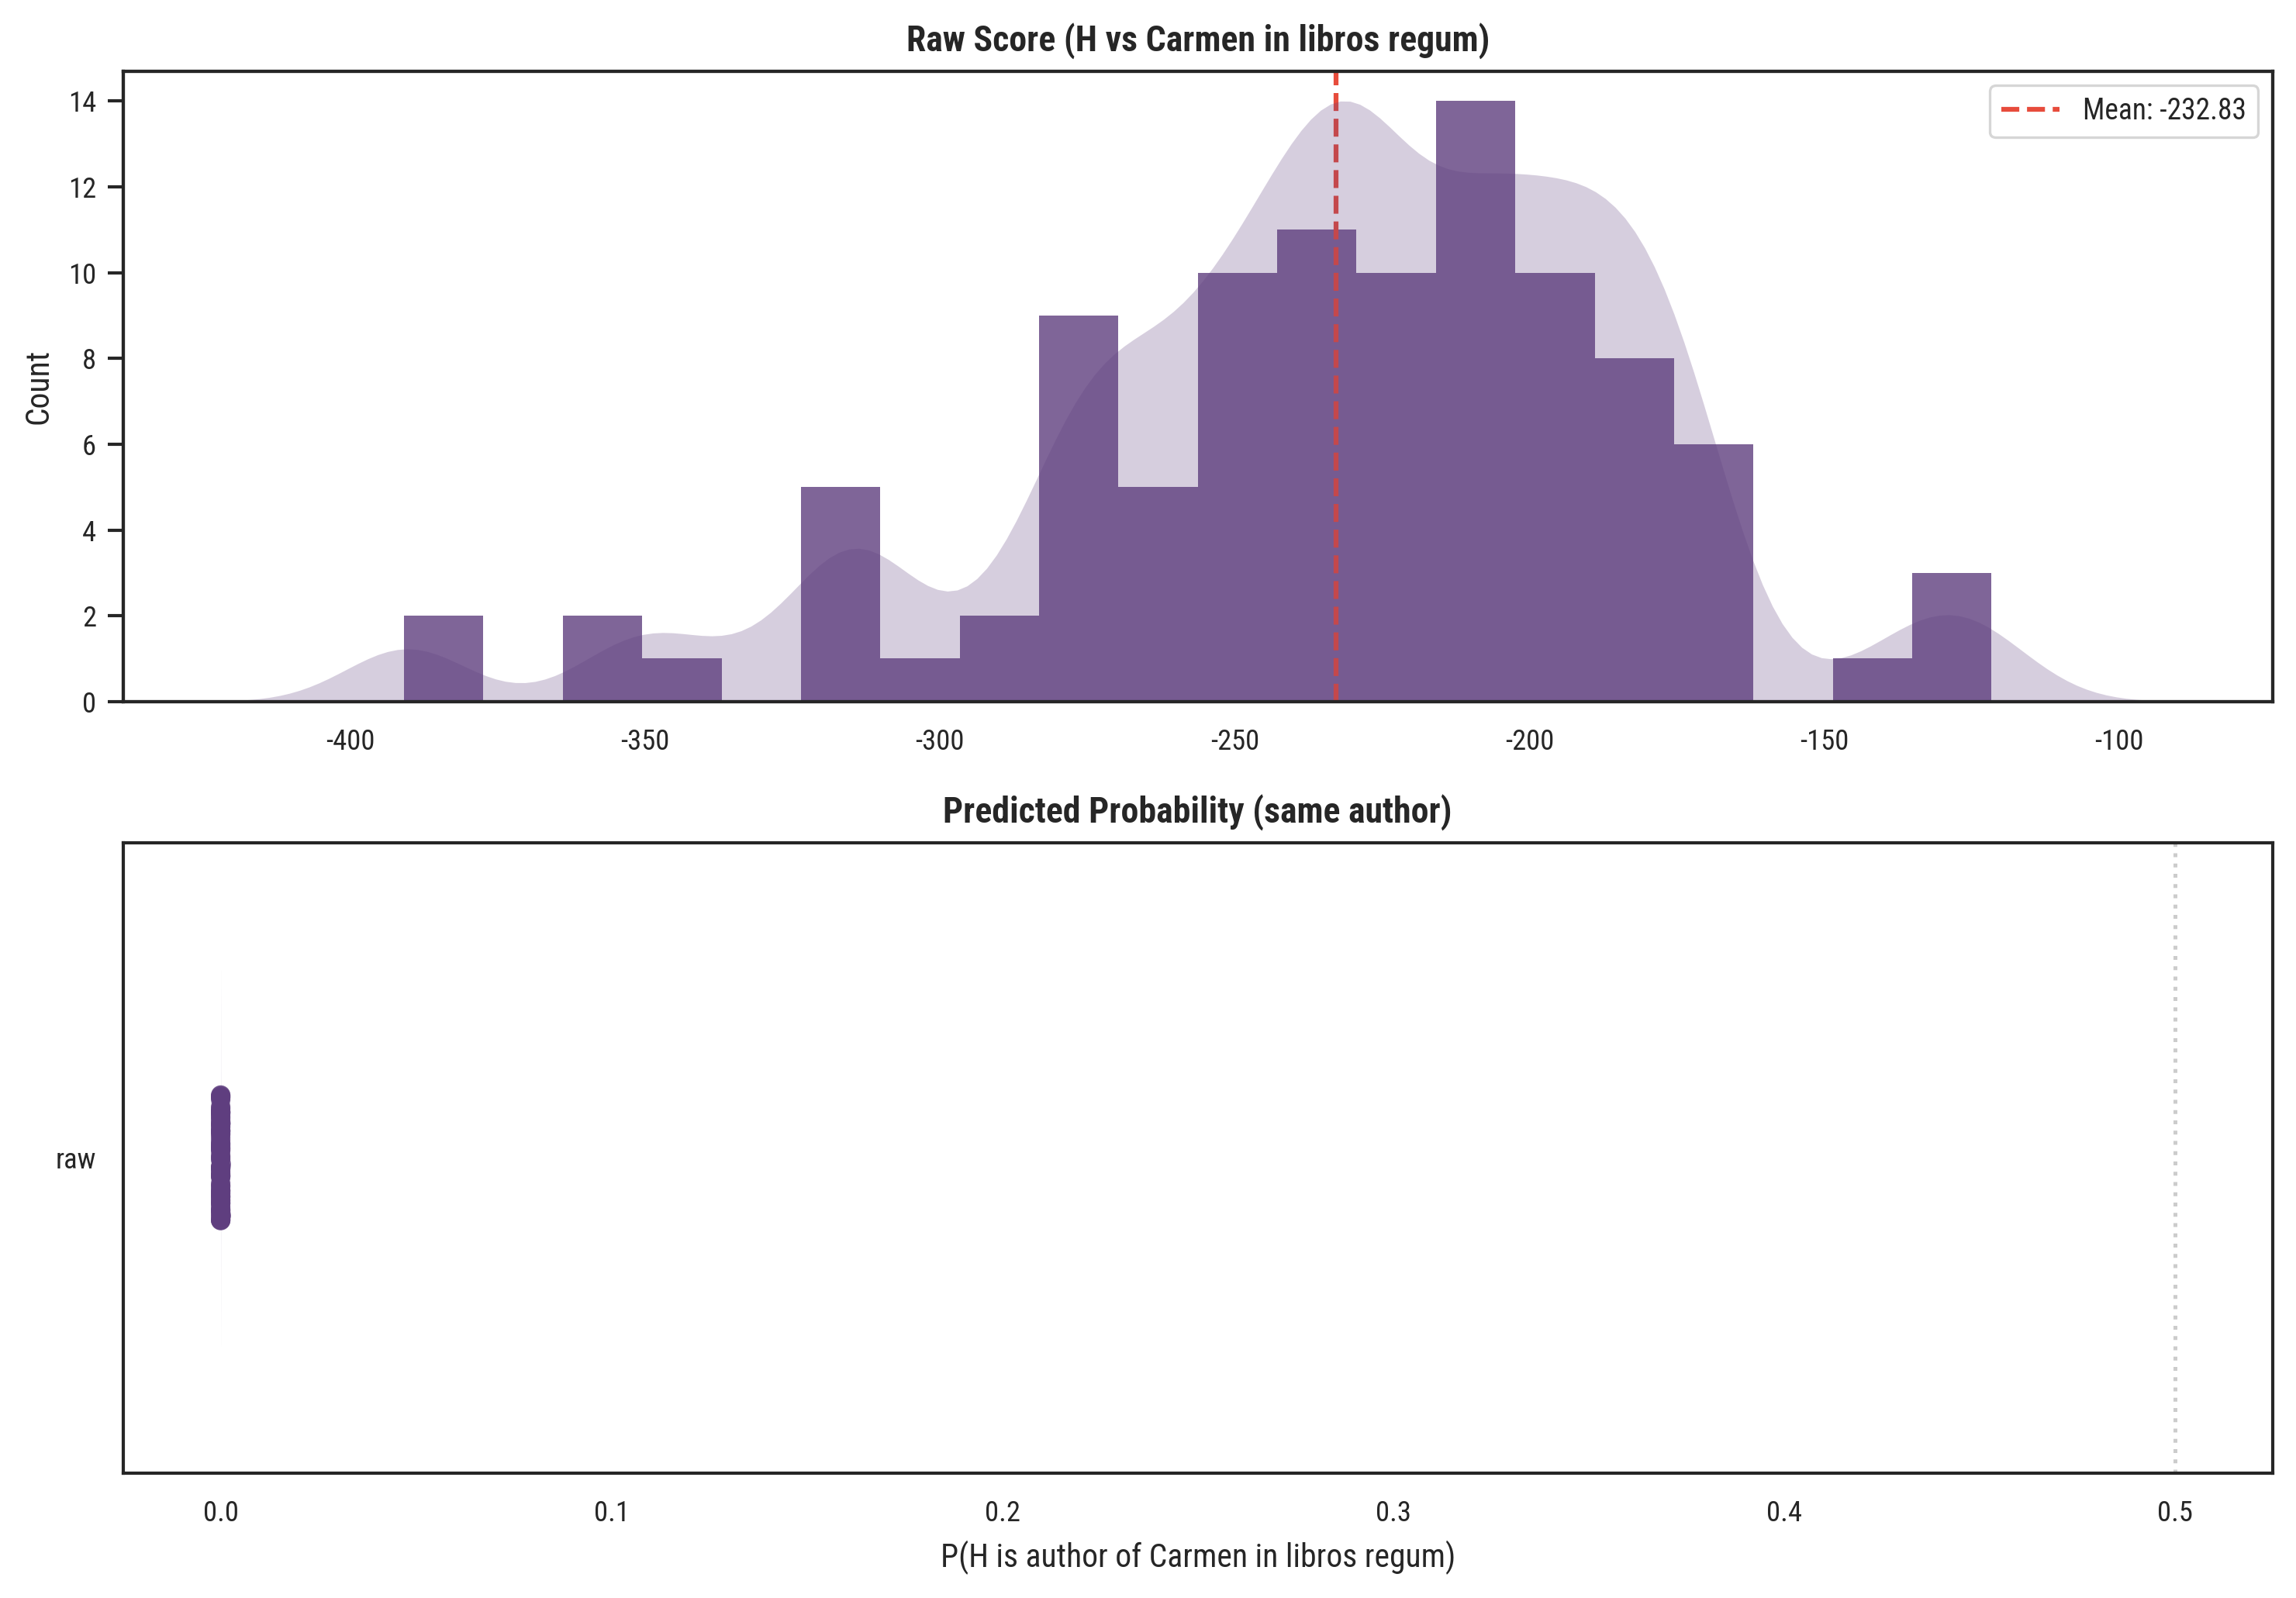

In [60]:
# Visualization: histplot of raw scores + stripplot/violin of probabilities
fig, axes = plt.subplots(2, 1, figsize=(10, 7), dpi=300)

for ax in axes:
    ax.grid(False)

color = "#5f3e7f"

# Row 1: Raw score distribution with KDE overlay
ax = axes[0]
sns.histplot(data=df, x="score", bins=20, ax=ax, color=color, alpha=0.8, linewidth=0)
ax2 = ax.twinx()
sns.kdeplot(
    data=df,
    x="score",
    ax=ax2,
    color=color,
    fill=True,
    linewidth=0,
    alpha=0.25,
    bw_adjust=0.5,
)
ax2.set_yticklabels([])
ax2.set_yticks([])
ax2.set_ylabel("")
ax.set_title("Raw Score (H vs Carmen in libros regum)", fontweight="bold", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
mean_val = df["score"].mean()
ax.axvline(
    mean_val,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.2f}",
)
ax.legend(loc="upper right", fontsize=9)

# Row 2: Probability stripplot + violin
ax = axes[1]
ax.grid(False)
df_plot = pd.DataFrame(
    {
        "probability": df["probability"].tolist(),
        "model": ["raw"] * len(df),
    }
)
sns.violinplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    width=0.6,
    inner=None,
    density_norm="width",
    alpha=0.4,
    linewidth=0,
    legend=False,
)
sns.stripplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    size=6,
    jitter=True,
    alpha=0.7,
    legend=False,
)
ax.set_title("Predicted Probability (same author)", fontweight="bold", fontsize=11)
ax.set_xlabel("P(H is author of Carmen in libros regum)")
ax.set_ylabel("")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Evaluate Against All Authors

Now run the same 100 evaluations against every other author in the test corpus. For authors with fewer than 2000 tokens, we use their total token count as `known_size`.

In [62]:
# Compute known_size for each author
author_sizes = {}
for author in sorted(test_corpus.get_unique_values("author")):
    author_corpus = test_corpus.filter_by_level("author", author)
    tokens = sum(len(s.text.split()) for s in author_corpus)
    known_size = min(2000, tokens)
    author_sizes[author] = known_size
    print(f"  {author:6s}: {tokens:6d} tokens → known_size={known_size}")

  AE    :   1480 tokens → known_size=1480
  ASt   :  12871 tokens → known_size=2000
  BB    :   2801 tokens → known_size=2000
  BBi   :   4273 tokens → known_size=2000
  BI    :   4139 tokens → known_size=2000
  BM    :   2244 tokens → known_size=2000
  BS    :   1800 tokens → known_size=1800
  EM    :   2463 tokens → known_size=2000
  H     :   2520 tokens → known_size=2000
  HA    :   2119 tokens → known_size=2000
  HM    :  12291 tokens → known_size=2000
  HW    :  20359 tokens → known_size=2000
  IS    :   3936 tokens → known_size=2000
  M     :   9413 tokens → known_size=2000
  NLC   :  14290 tokens → known_size=2000
  PDE   :   3522 tokens → known_size=2000
  PR    :  26521 tokens → known_size=2000
  QS    :   8187 tokens → known_size=2000
  RDV   :   2382 tokens → known_size=2000
  RL    :  15760 tokens → known_size=2000
  RT    :  20464 tokens → known_size=2000
  SAC   :   2174 tokens → known_size=2000
  SR    :   9123 tokens → known_size=2000
  U1    :   1468 tokens → known_si

In [63]:
# Define the per-author evaluation function
@ray.remote
def run_evaluation_for_author(
    seed: int,
    known_author: str,
    known_size: int,
    target_tokens: int = 1000,
) -> dict:
    """Run a single AV evaluation: Carmen in libros regum vs a given known author."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    q_corpus = sample_corpus_to_token_count(cilr_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity=known_author,
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=known_size,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "author": known_author,
        "score": result["score"],
        "known_size": known_size,
    }

In [64]:
N_EVALUATIONS = 100
# Run evaluations for all authors
ray.init()
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

master_rng = np.random.default_rng(123)

all_tasks = []
task_info = []  # (author, seed) for each task

for author, known_size in author_sizes.items():
    for i in range(N_EVALUATIONS):
        seed = master_rng.integers(0, 2**32 - 1)
        all_tasks.append(
            run_evaluation_for_author.remote(seed, author, known_size, TARGET_TOKENS)
        )
        task_info.append(author)

print(f"Created {len(all_tasks)} tasks for {len(author_sizes)} authors")

# Execute all tasks
all_results = []
for _ in tqdm(range(len(all_tasks)), desc="All evaluations"):
    ready, _ = ray.wait(all_tasks, num_returns=1)
    result = ray.get(ready[0])
    all_results.append(result)
    all_tasks.remove(ready[0])

print(f"✓ Completed {len(all_results)} evaluations")
ray.shutdown()

2026-09-14 17:05:57,492	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs
Created 2700 tasks for 27 authors


All evaluations:   0%|                                | 0/2700 [00:00<?, ?it/s](pid=16027) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=16027)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=16027) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=16027)   from pandas.core import (
All evaluations: 100%|█████████████████████| 2700/2700 [16:57<00:00,  2.65it/s]
(pid=16025) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=16025)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x a

✓ Completed 2700 evaluations


In [65]:
# Convert to DataFrame and compute probabilities
df_all = pd.DataFrame(all_results)
df_all["probability"] = model.predict_proba(df_all["score"].values.reshape(-1, 1))[:, 1]

# Summary: mean probability per author
summary = df_all.groupby("author")["probability"].agg(["mean", "std", "count"]).round(4)
summary = summary.sort_values("mean", ascending=False)
print("\n=== Mean Predicted Probability by Author ===")
print(summary)


=== Mean Predicted Probability by Author ===
          mean     std  count
author                       
U4      0.9918  0.0269    100
AE      0.9737  0.0702    100
BM      0.7955  0.2544    100
PR      0.4619  0.3715    100
ASt     0.2201  0.3021    100
HA      0.1410  0.2145    100
SAC     0.0943  0.1475    100
QS      0.0153  0.0852    100
RT      0.0129  0.0469    100
RL      0.0041  0.0138    100
BI      0.0035  0.0169    100
SR      0.0031  0.0160    100
BB      0.0023  0.0078    100
PDE     0.0006  0.0014    100
IS      0.0004  0.0025    100
U3      0.0000  0.0000    100
U2      0.0000  0.0001    100
U1      0.0000  0.0000    100
NLC     0.0000  0.0000    100
RDV     0.0000  0.0000    100
BBi     0.0000  0.0000    100
HW      0.0000  0.0002    100
HM      0.0000  0.0000    100
H       0.0000  0.0000    100
EM      0.0000  0.0000    100
BS      0.0000  0.0000    100
M       0.0000  0.0000    100


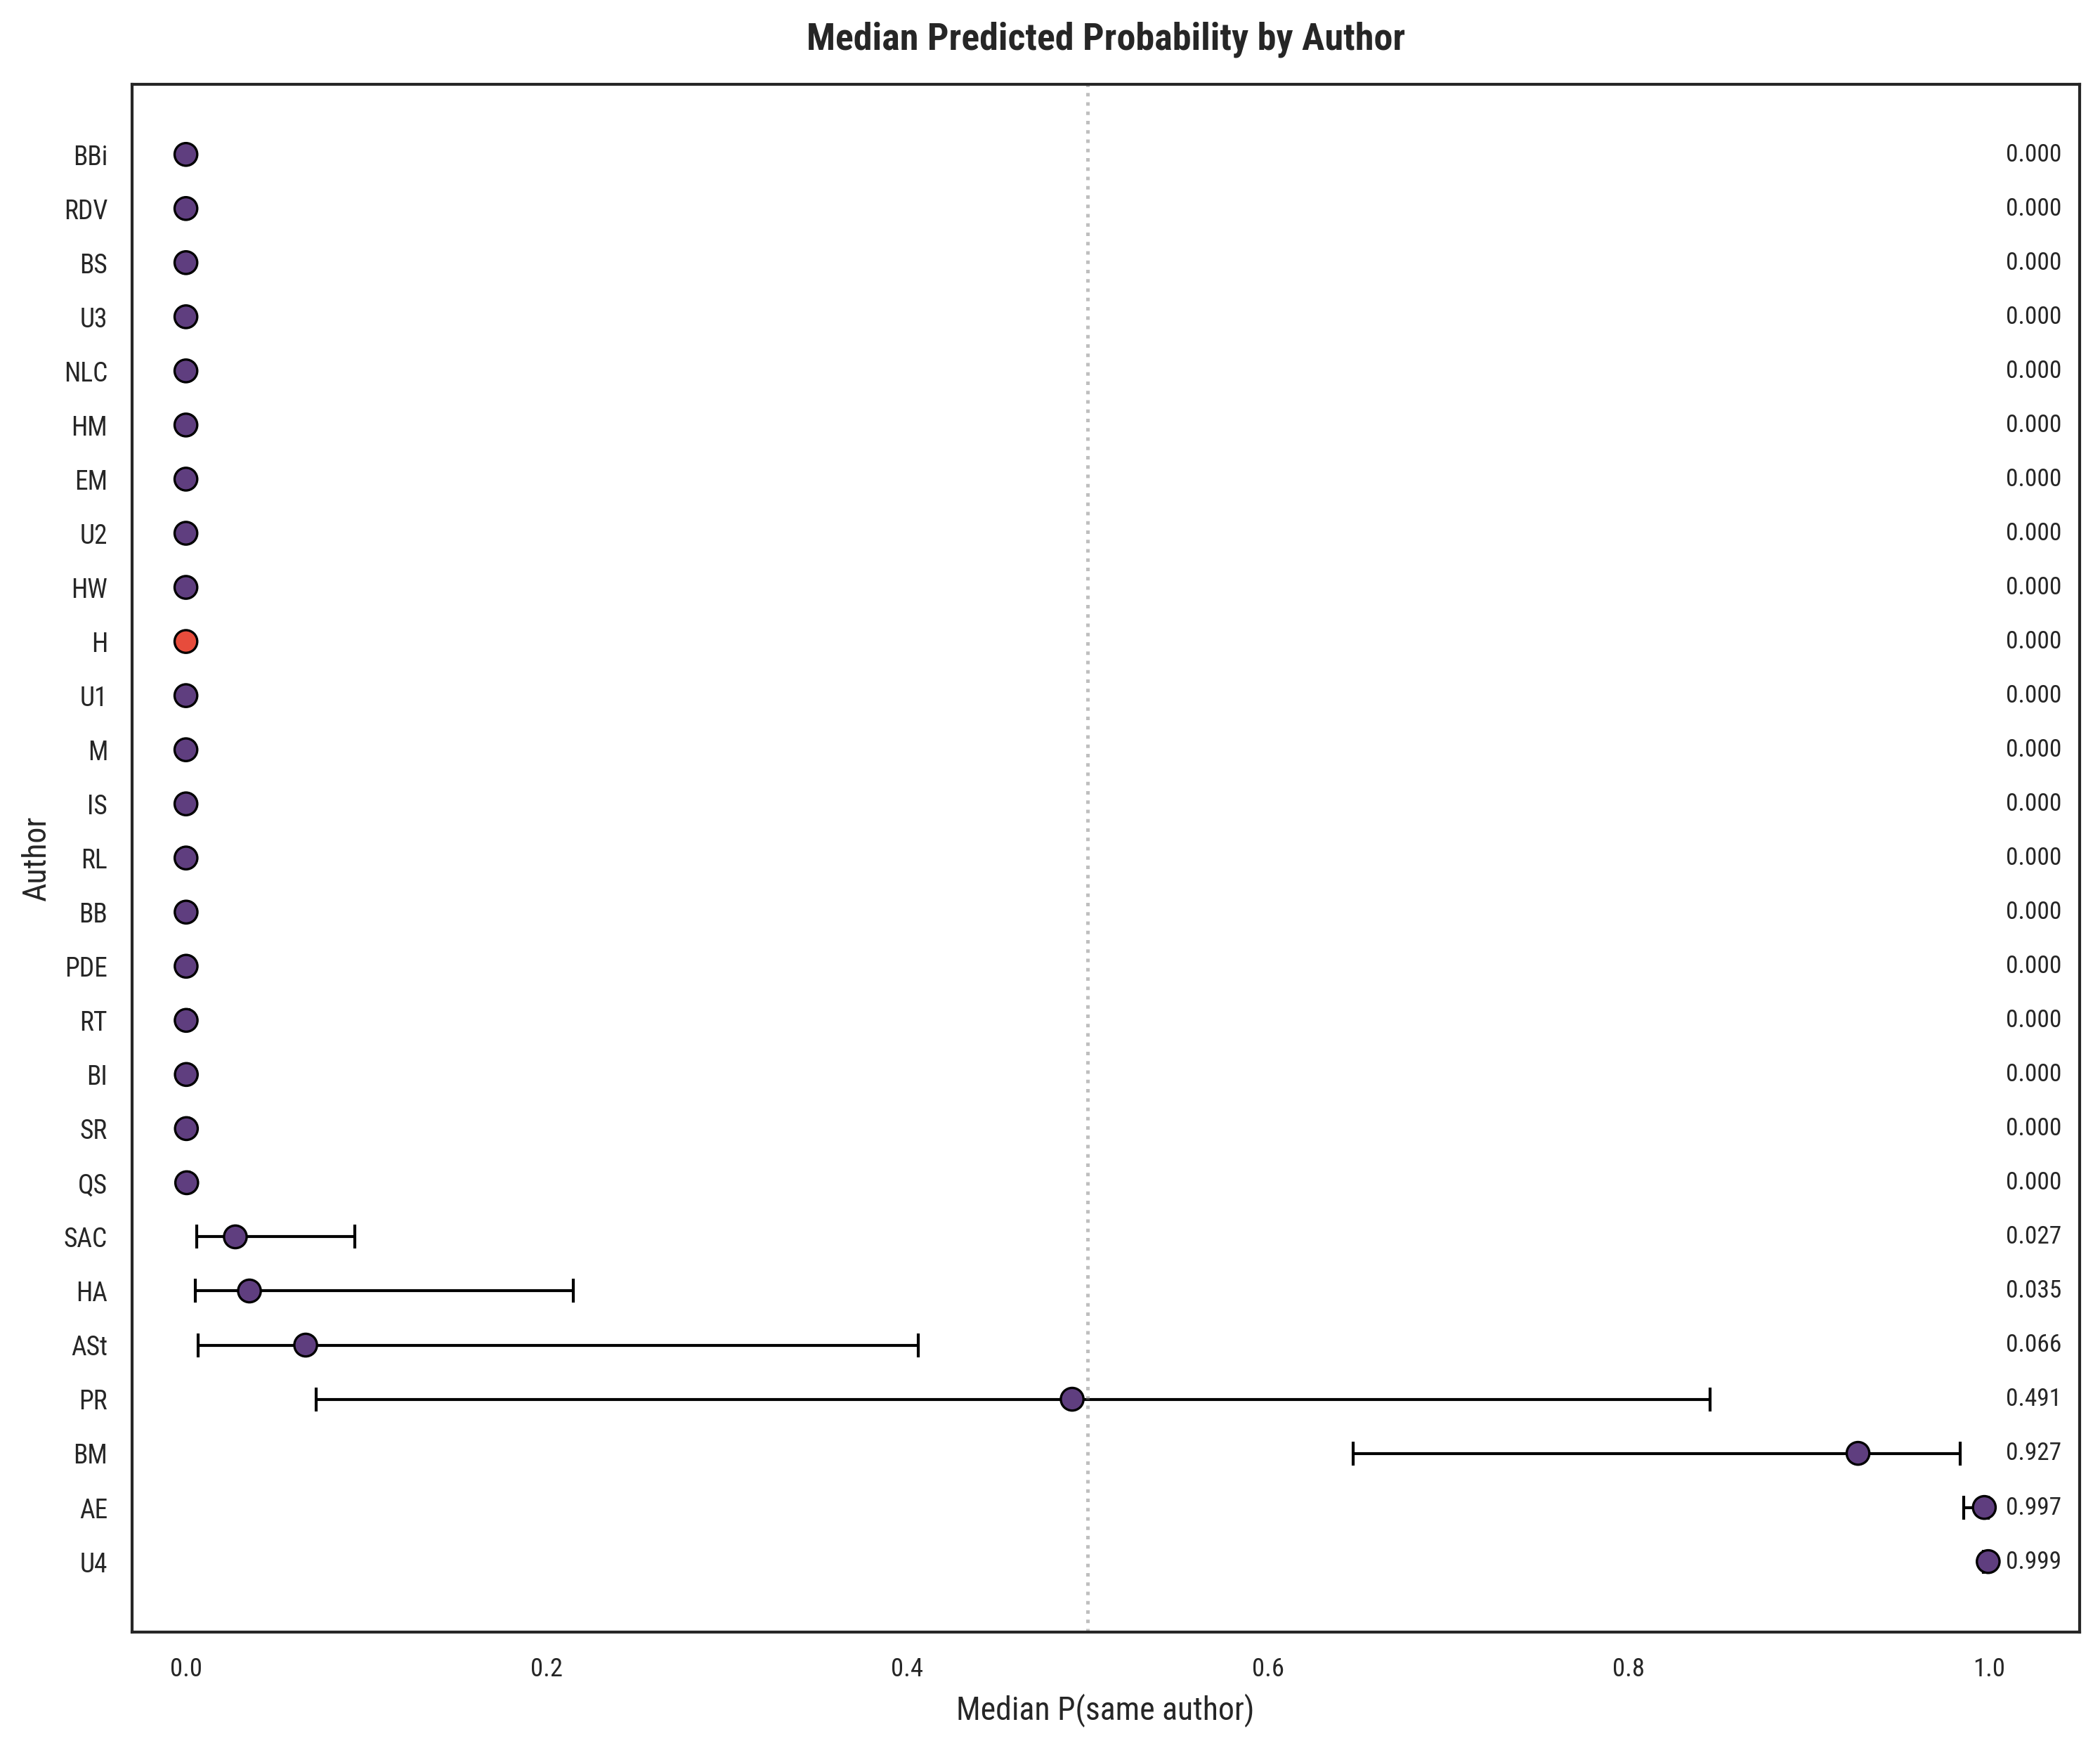

In [66]:
# Visualization: median probability per author with IQR whiskers
import math

# Compute stats per author
stats = df_all.groupby("author")["probability"].agg(
    ["median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]
)
stats.columns = ["median", "q25", "q75"]
stats = stats.sort_values("median", ascending=True)
authors_ordered = stats.index.tolist()

# Dynamic figure height: more authors = taller figure
fig_height = max(8, 0.32 * len(authors_ordered))
fig, ax = plt.subplots(figsize=(12, fig_height), dpi=300)

ax.grid(False)

# Color: highlight H differently
colors = ["#e74c3c" if a == "H" else "#5f3e7f" for a in authors_ordered]

# IQR whiskers
for i, author in enumerate(authors_ordered):
    row = stats.loc[author]
    ax.plot(
        [row["q25"], row["q75"]],
        [i, i],
        color="black",
        linewidth=1,
        solid_capstyle="round",
        zorder=2,
    )
    for q in [row["q25"], row["q75"]]:
        ax.plot(q, i, "|", color="black", markersize=8, markeredgewidth=1, zorder=3)

# Median dots
ax.scatter(
    stats["median"].values,
    range(len(authors_ordered)),
    c=colors,
    s=60,
    zorder=5,
    edgecolors="black",
    linewidth=0.8,
)

ax.set_yticks(range(len(authors_ordered)))
ax.set_yticklabels(authors_ordered, fontsize=9)

# Put lowest values at the top and highest at the bottom
ax.invert_yaxis()

ax.set_title(
    "Median Predicted Probability by Author",
    fontweight="bold",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Median P(same author)", fontsize=11)
ax.set_ylabel("Author", fontsize=11)

# Reference line at 0.5
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.5)

# Leave extra room on the right for value labels
ax.set_xlim(-0.03, 1.05)
ax.set_xticks(np.arange(0, 1.01, 0.2))

# Add value labels on the right side of the plot
for i, val in enumerate(stats["median"].values):
    ax.text(
        1.04,
        i,
        f"{val:.3f}",
        va="center",
        ha="right",
        fontsize=8.5,
    )

# Improve margins
plt.subplots_adjust(left=0.18, right=0.95, top=0.92, bottom=0.07)
plt.savefig(f"Median_probability.png", dpi=300, bbox_inches="tight")
plt.show()